# Projeto - Sprint 8: Análise de Negócio

In [23]:
import pandas as pd
import matplotlib.pyplot as plt

In [24]:
visits = pd.read_csv('visits_log_us.csv')
orders = pd.read_csv('orders_log_us.csv')
costs = pd.read_csv('costs_us.csv')

In [25]:
print(visits.info())

<class 'pandas.DataFrame'>
RangeIndex: 359400 entries, 0 to 359399
Data columns (total 5 columns):
 #   Column     Non-Null Count   Dtype 
---  ------     --------------   ----- 
 0   Device     359400 non-null  str   
 1   End Ts     359400 non-null  str   
 2   Source Id  359400 non-null  int64 
 3   Start Ts   359400 non-null  str   
 4   Uid        359400 non-null  uint64
dtypes: int64(1), str(3), uint64(1)
memory usage: 28.9 MB
None


In [26]:
print(orders.info())

<class 'pandas.DataFrame'>
RangeIndex: 50415 entries, 0 to 50414
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Buy Ts   50415 non-null  str    
 1   Revenue  50415 non-null  float64
 2   Uid      50415 non-null  uint64 
dtypes: float64(1), str(1), uint64(1)
memory usage: 2.1 MB
None


In [27]:
print(costs.info())

<class 'pandas.DataFrame'>
RangeIndex: 2542 entries, 0 to 2541
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   source_id  2542 non-null   int64  
 1   dt         2542 non-null   str    
 2   costs      2542 non-null   float64
dtypes: float64(1), int64(1), str(1)
memory usage: 84.5 KB
None


In [28]:
visits.columns = ['device', 'end_ts', 'source_id', 'start_ts', 'uid']
orders.columns = ['buy_ts', 'revenue', 'uid']

visits['start_ts'] = pd.to_datetime(visits['start_ts'])
visits['end_ts'] = pd.to_datetime(visits['end_ts'])

orders['buy_ts'] = pd.to_datetime(orders['buy_ts'])

costs['dt'] = pd.to_datetime(costs['dt'])

print(visits.info())
print(orders.info())

<class 'pandas.DataFrame'>
RangeIndex: 359400 entries, 0 to 359399
Data columns (total 5 columns):
 #   Column     Non-Null Count   Dtype         
---  ------     --------------   -----         
 0   device     359400 non-null  str           
 1   end_ts     359400 non-null  datetime64[us]
 2   source_id  359400 non-null  int64         
 3   start_ts   359400 non-null  datetime64[us]
 4   uid        359400 non-null  uint64        
dtypes: datetime64[us](2), int64(1), str(1), uint64(1)
memory usage: 15.9 MB
None
<class 'pandas.DataFrame'>
RangeIndex: 50415 entries, 0 to 50414
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype         
---  ------   --------------  -----         
 0   buy_ts   50415 non-null  datetime64[us]
 1   revenue  50415 non-null  float64       
 2   uid      50415 non-null  uint64        
dtypes: datetime64[us](1), float64(1), uint64(1)
memory usage: 1.2 MB
None


In [29]:
for nome, df in [('visits', visits), ('orders', orders), ('costs', costs)]:
    print(f"{nome} - duplicados: {df.duplicated().sum()} | ausentes: {df.isna().sum().sum()}")

visits - duplicados: 0 | ausentes: 0
orders - duplicados: 0 | ausentes: 0
costs - duplicados: 0 | ausentes: 0


As três bases de dados (visits, orders e costs) foram importadas e inspecionadas. Foi padronizado as colunas, Renomeando-as para o padrão snake_case (sem espaços e com letras minúsculas). Garantindo a consistência e facilitando muito a manipulação das variáveis durante a análise.  
Por fim, as colunas que continham informações de data e hora foram convertidas para o tipo datetime, possiblitando a capacidade de fazer agrupamentos e cálculos matemáticos com o tempo nas etapas seguintes.

In [30]:
visits['session_date'] = visits['start_ts'].dt.date
visits['session_week'] = visits['start_ts'].dt.strftime('%Y-%U')
visits['session_month'] = visits['start_ts'].dt.strftime('%Y-%m')

dau_total = visits.groupby('session_date')['uid'].nunique().mean()
wau_total = visits.groupby('session_week')['uid'].nunique().mean()
mau_total = visits.groupby('session_month')['uid'].nunique().mean()

print(f'DAU (Média de usuários por dia): {int(dau_total)}')
print(f'WAU (Média de usuários por semana): {int(wau_total)}')
print(f'MAU (Média de usuários por mês): {int(mau_total)}')

DAU (Média de usuários por dia): 907
WAU (Média de usuários por semana): 5612
MAU (Média de usuários por mês): 23228


In [31]:
sessions_per_day = visits.groupby('session_date')['uid'].count()
mean_sessions_per_day = sessions_per_day.mean()
sessions_per_user = mean_sessions_per_day / dau_total

print(f'Média total de sessões por dia: {int(mean_sessions_per_day)}')
print(f'Média de sessões por usuário por dia: {sessions_per_user:.2f}')

Média total de sessões por dia: 987
Média de sessões por usuário por dia: 1.09


In [32]:
visits['session_duration_sec'] = (visits['end_ts'] - visits['start_ts']).dt.seconds
asl_mean = visits['session_duration_sec'].mean()

print(f'Duração média da sessão: {asl_mean:.2f} segundos')

Duração média da sessão: 643.51 segundos


In [33]:
sticky_wau = (dau_total / wau_total) * 100
sticky_mau = (dau_total / mau_total) * 100

print(f'Frequência de retorno semanal (Sticky Factor WAU): {sticky_wau:.2f}%')
print(f'Frequência de retorno mensal (Sticky Factor MAU): {sticky_mau:.2f}%')

Frequência de retorno semanal (Sticky Factor WAU): 16.18%
Frequência de retorno mensal (Sticky Factor MAU): 3.91%


Nesta etapa, foi utilizado métodos de agrupamento e filtragem do Pandas para entender o comportamento do público, evitando lógicas excessivamente complexas.  
Foi extraído recortes de tempo das datas para calcular com facilidade a média de usuários ativos por dia (DAU), semana (WAU) e mês (MAU), assim como o volume de sessões geradas.  
Depois, Aplicou-se uma operação básica de subtração entre o início e o fim da visita para encontrar a duração em segundos, extraindo a média para entender o comportamento real.  
Finalizando com o cálculo do Sticky Factor (DAU/WAU e DAU/MAU), que mede a frequência com que os usuários retornam à plataforma semanal e mensalmente.

In [34]:
primeiro_acesso = visits.groupby('uid')['start_ts'].min().reset_index()
primeiro_acesso.columns = ['uid', 'first_visit']

primeira_compra = orders.groupby('uid')['buy_ts'].min().reset_index()
primeira_compra.columns = ['uid', 'first_order']

conversao = pd.merge(primeiro_acesso, primeira_compra, on='uid', how='inner')
conversao['days_to_buy'] = (conversao['first_order'] - conversao['first_visit']).dt.days

print("Resumo estatístico do tempo de conversão (em dias):")
print(conversao['days_to_buy'].describe())
print("\nTempo mais comum para a conversão (Moda):", conversao['days_to_buy'].mode()[0], "dias")

Resumo estatístico do tempo de conversão (em dias):
count    36523.000000
mean        16.729869
std         46.959088
min          0.000000
25%          0.000000
50%          0.000000
75%          2.000000
max        363.000000
Name: days_to_buy, dtype: float64

Tempo mais comum para a conversão (Moda): 0 dias


In [35]:
orders['order_month'] = orders['buy_ts'].dt.strftime('%Y-%m')

total_pedidos_mes = orders.groupby('order_month')['uid'].count()
clientes_unicos_mes = orders.groupby('order_month')['uid'].nunique()

pedidos_por_cliente_mes = total_pedidos_mes / clientes_unicos_mes

print("Média de pedidos por cliente a cada mês:")
print(pedidos_por_cliente_mes)

Média de pedidos por cliente a cada mês:
order_month
2017-06    1.163618
2017-07    1.191028
2017-08    1.227582
2017-09    1.231636
2017-10    1.214759
2017-11    1.244557
2017-12    1.258195
2018-01    1.211134
2018-02    1.240254
2018-03    1.273858
2018-04    1.192784
2018-05    1.226298
2018-06    1.000000
Name: uid, dtype: float64


In [36]:
ticket_medio_geral = orders['revenue'].mean()
print(f'Volume médio geral de uma compra (Ticket Médio): ${ticket_medio_geral:.2f}')

ticket_medio_mes = orders.groupby('order_month')['revenue'].mean()

print("\nVolume médio de uma compra por mês:")
print(ticket_medio_mes)

Volume médio geral de uma compra (Ticket Médio): $5.00

Volume médio de uma compra por mês:
order_month
2017-06    4.060106
2017-07    5.306589
2017-08    4.847139
2017-09    5.416448
2017-10    4.928280
2017-11    4.783518
2017-12    5.852139
2018-01    4.112927
2018-02    4.840095
2018-03    5.413930
2018-04    5.150645
2018-05    4.771279
2018-06    3.420000
Name: revenue, dtype: float64


In [37]:
primeira_compra = orders.groupby('uid')['buy_ts'].min().dt.strftime('%Y-%m').reset_index()
primeira_compra.columns = ['uid', 'first_order_month']

orders_ltv = pd.merge(orders, primeira_compra, on='uid')
receita_por_coorte = orders_ltv.groupby('first_order_month')['revenue'].sum().reset_index()

tamanho_coorte = orders_ltv.groupby('first_order_month')['uid'].nunique().reset_index()
tamanho_coorte.columns = ['first_order_month', 'n_buyers']
ltv_tabela = pd.merge(receita_por_coorte, tamanho_coorte, on='first_order_month')
ltv_tabela['ltv'] = ltv_tabela['revenue'] / ltv_tabela['n_buyers']

print("LTV por Coorte (Mês da primeira compra):")
print(ltv_tabela[['first_order_month', 'ltv']])

LTV por Coorte (Mês da primeira compra):
   first_order_month        ltv
0            2017-06  11.879234
1            2017-07   8.386854
2            2017-08   8.471723
3            2017-09  13.435227
4            2017-10   6.360242
5            2017-11   6.395244
6            2017-12   7.639913
7            2018-01   4.940151
8            2018-02   4.587921
9            2018-03   5.455253
10           2018-04   5.189196
11           2018-05   4.660562
12           2018-06   3.420000


In [38]:
custo_total = costs['costs'].sum()
print(f'Total gasto com marketing: ${custo_total:.2f}\n')

custo_por_origem = costs.groupby('source_id')['costs'].sum().sort_values(ascending=False)
print(f'Total gasto por origem de anúncio:\n{custo_por_origem}\n')

costs['cost_month'] = costs['dt'].dt.strftime('%Y-%m')
custo_por_mes = costs.groupby('cost_month')['costs'].sum()
print(f'Total gasto ao longo do tempo (por mês):\n{custo_por_mes}')

Total gasto com marketing: $329131.62

Total gasto por origem de anúncio:
source_id
3     141321.63
4      61073.60
5      51757.10
2      42806.04
1      20833.27
10      5822.49
9       5517.49
Name: costs, dtype: float64

Total gasto ao longo do tempo (por mês):
cost_month
2017-06    18015.00
2017-07    18240.59
2017-08    14790.54
2017-09    24368.91
2017-10    36322.88
2017-11    37907.88
2017-12    38315.35
2018-01    33518.52
2018-02    32723.03
2018-03    30415.27
2018-04    22289.38
2018-05    22224.27
Name: costs, dtype: float64


In [39]:
custo_por_origem = costs.groupby('source_id')['costs'].sum()

primeiros_acessos = visits.sort_values('start_ts').drop_duplicates('uid', keep='first')
origem_dos_usuarios = primeiros_acessos[['uid', 'source_id']]

compradores_unicos = orders[['uid']].drop_duplicates()
compradores_com_origem = pd.merge(compradores_unicos, origem_dos_usuarios, on='uid', how='inner')

clientes_por_origem = compradores_com_origem.groupby('source_id')['uid'].count()
cac_por_origem = (custo_por_origem / clientes_por_origem).dropna().sort_values(ascending=False)

print(f'Custo de Aquisição de Clientes (CAC) por origem:\n{cac_por_origem}\n')

Custo de Aquisição de Clientes (CAC) por origem:
source_id
3     13.493901
2     12.209367
5      7.467479
1      7.186364
4      5.931779
9      5.071222
10     4.381106
dtype: float64



In [40]:
pedidos_com_origem = pd.merge(orders, origem_dos_usuarios, on='uid', how='inner')
receita_por_origem = pedidos_com_origem.groupby('source_id')['revenue'].sum()

roi_por_origem = (receita_por_origem / custo_por_origem)
roi_por_origem_pct = (roi_por_origem * 100).dropna().sort_values(ascending=False)

print(f'Retorno sobre o Investimento (ROI) por origem em porcentagem:\n{roi_por_origem_pct}')

Retorno sobre o Investimento (ROI) por origem em porcentagem:
source_id
1     149.235094
2     109.619133
9     104.384421
5     101.674978
4      92.833614
10     76.433450
3      38.572468
dtype: float64


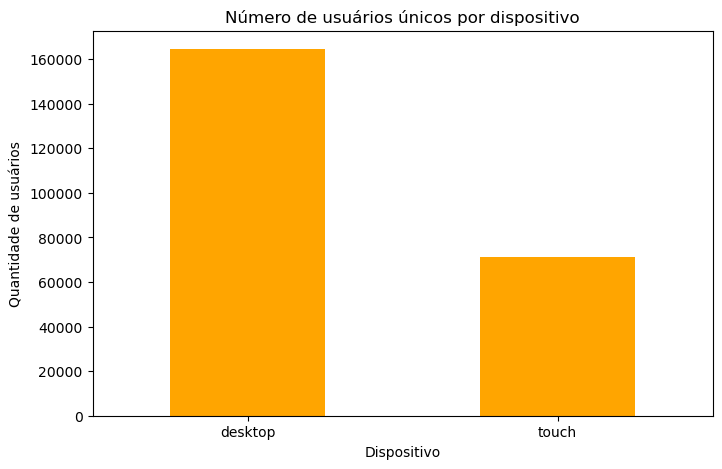

In [41]:
usuarios_por_dispositivo = visits.groupby('device')['uid'].nunique()

usuarios_por_dispositivo.plot(kind='bar', figsize=(8, 5), color='orange')
plt.title('Número de usuários únicos por dispositivo')
plt.xlabel('Dispositivo')
plt.ylabel('Quantidade de usuários')
plt.xticks(rotation=0)
plt.show()

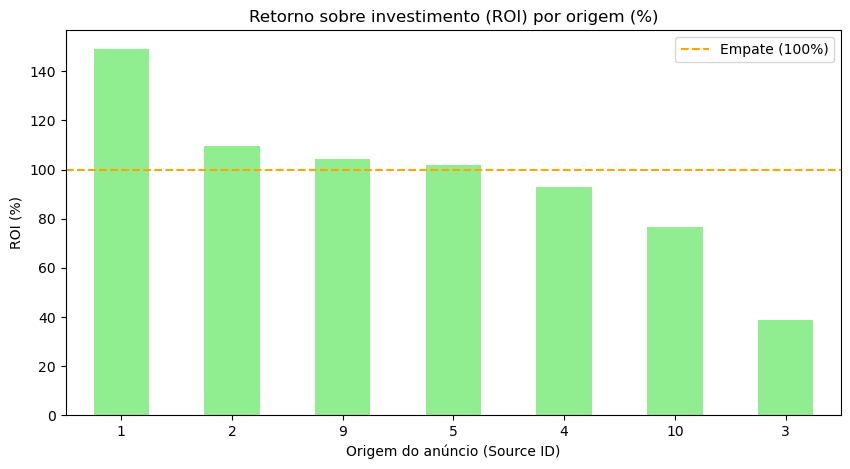

In [42]:
roi_por_origem_pct.plot(kind='bar', figsize=(10, 5), color='lightgreen')
plt.title('Retorno sobre investimento (ROI) por origem (%)')
plt.xlabel('Origem do anúncio (Source ID)')
plt.ylabel('ROI (%)')

plt.axhline(100, color='orange', linestyle='--', label='Empate (100%)')
plt.legend()
plt.xticks(rotation=0)
plt.show()

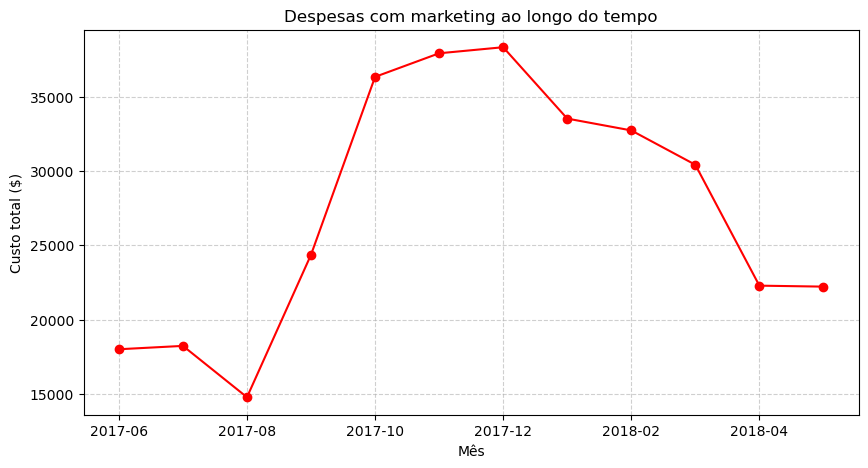

In [43]:
custo_por_mes.plot(kind='line', figsize=(10, 5), marker='o', color='red')
plt.title('Despesas com marketing ao longo do tempo')
plt.xlabel('Mês')
plt.ylabel('Custo total ($)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

## Conclusão e Recomendações Estratégicas de Marketing

Para fundamentar a decisão de investimento, a análise concentrou-se prioritariamente em duas métricas financeiras: ROI (Retorno sobre o Investimento) e CAC (Custo de Aquisição de Clientes), apoiadas pela visão geral do LTV (Lifetime Value).  
A escolha por esses indicadores ocorreu porque métricas puramente de tráfego (como DAU, WAU ou volume de sessões) não refletem a viabilidade financeira do negócio. Uma origem de anúncio pode trazer um grande volume de acessos, mas se o custo para adquirir esse cliente (CAC) for maior do que o valor que ele gasta na plataforma (LTV), a empresa perde dinheiro. Qualquer canal com retorno superior a 100% indica lucratividade, enquanto valores menores representam prejuízo.  
Ao cruzar os custos com a receita gerada, ficou claro que o gasto com marketing não é proporcional ao retorno. Algumas fontes absorvem orçamento da Y.Afisha, mas não se pagam. Em contrapartida, as origens 1, 2, 9 e 5 demonstraram eficiência, conseguindo converter usuários em compradores gerando lucro real (com destaque absoluto para a origem 1, que alcançou quase 150% de ROI). Além disso, a análise de dispositivos revelou que a maior parte do público acessa via desktop.  
Recomenda-se, portanto, que o departamento de marketing realize uma otimização imediata do orçamento atual, direcionando o foco e o capital para as origens 1, 2, 9 e 5, pois provaram ser os canais mais saudáveis da operação, entregando o melhor ROI.  
Assim como, deve-se interromper ou reduzir drasticamente os investimentos nas origens 4, 10 e 3, que estão drenando os recursos da empresa sem trazer o retorno financeiro correspondente (com atenção crítica de pausa imediata na origem 3).  
O montante financeiro que era desperdiçado nesses canais ineficientes deve ser integralmente transferido para as origens vencedoras para maximizar a aquisição de clientes lucrativos.